# Задача 4.4 — Монета до двух одинаковых подряд

---

## 1. Условие

«Симметричную» монету бросают до тех пор, пока она не выпадет дважды одной и той же стороной подряд. Построить вероятностную модель $(\Omega, P(\cdot))$ и найти вероятность того, что потребуется **чётное** число бросаний.

**Ответ:** $2/3$.

---

## 2. Теоретическая часть

### Модель

Исход — конечная последовательность вида $\underbrace{\text{Г О Г О} \dots}_{\text{чередование}} X X$, где $X \in \{\text{Г}, \text{О}\}$, и до последних двух символов стороны чередуются.

- Длина 2: $\text{ГГ}, \text{ОО}$ — вероятность $2 \cdot \tfrac14 = \tfrac12$.
- Длина $n \ge 2$: первые $n-2$ бросаний строго чередуются (2 варианта), затем два одинаковых. Вероятность $2 \cdot \left(\tfrac12\right)^n = \left(\tfrac12\right)^{n-1}$.

### Чётное число бросаний

$$
P = \sum_{m \ge 1} P(X = 2m) = \sum_{m \ge 1} \left(\tfrac12\right)^{2m-1}
= \frac{1/2}{1 - 1/4} = \frac{2}{3}.
$$

---

## 3. Решение

P(чётное число бросаний) = 0.6666666666666666 = 2/3


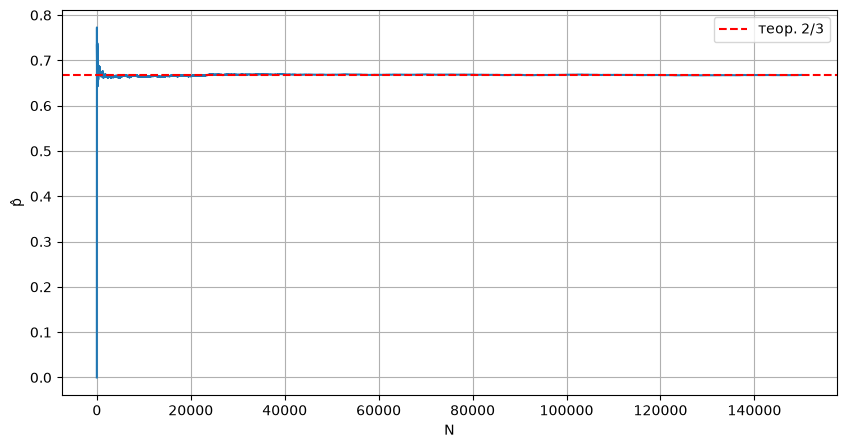

In [3]:
import numpy as np
import matplotlib.pyplot as plt

P_even = (1/2) / (1 - 1/4)
print(f"P(чётное число бросаний) = {P_even} = 2/3")

def simulate(N, seed=0):
    rng = np.random.default_rng(seed)
    hits = np.zeros(N, dtype=bool)
    for i in range(N):
        prev = None
        k = 0
        while True:
            cur = rng.integers(0, 2)  # 0 или 1
            k += 1
            if cur == prev:    # две одинаковые подряд
                break
            prev = cur
        hits[i] = (k % 2 == 0)
    return hits

N = 150_000
h = simulate(N, seed=3)
f = np.cumsum(h) / np.arange(1, N+1)

plt.figure(figsize=(10, 5))
plt.plot(f)
plt.axhline(P_even, color="r", ls="--", label="теор. 2/3")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.show()